# Full centered and uncentered LTO analysis

## Setup

In [1]:
import gc
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from tqdm.auto import tqdm

from google.colab import drive

drive.mount("/content/gdrive")

ROOT = Path(
    "/content/gdrive/MyDrive/"
    "gemma3_1b_it_gsm8k_raw26_v3_lean"
)
RECORDS_DIR = ROOT / "full" / "records"
RAW_DIR = ROOT / "full" / "raw_layer_outputs"
OUTPUT_DIR = ROOT / "analysis_lto_full"
CACHE_DIR = OUTPUT_DIR / "metric_cache"
FIGURE_DIR = OUTPUT_DIR / "figures"

PHASES = ("early", "middle", "late", "full")
LABELS = ("Correct", "Incorrect")
CHUNK_SIZE = 256
EPS = 1e-12

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

for directory in (
    OUTPUT_DIR,
    CACHE_DIR,
    FIGURE_DIR,
):
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )

if not RECORDS_DIR.is_dir():
    raise FileNotFoundError(RECORDS_DIR)

if not RAW_DIR.is_dir():
    raise FileNotFoundError(RAW_DIR)

print("Device:", DEVICE)
print("Raw folder:", RAW_DIR)
print("Output:", OUTPUT_DIR)

Mounted at /content/gdrive
Device: cuda
Raw folder: /content/gdrive/MyDrive/gemma3_1b_it_gsm8k_raw26_v3_lean/full/raw_layer_outputs
Output: /content/gdrive/MyDrive/gemma3_1b_it_gsm8k_raw26_v3_lean/analysis_lto_full


## Load full dataset index

In [2]:
def parse_correct(value):
    if isinstance(value, (bool, np.bool_)):
        return bool(value)

    if isinstance(value, (int, float, np.number)):
        return bool(value)

    if isinstance(value, str):
        value = value.strip().lower()

        if value in {"true", "correct", "1", "yes"}:
            return True

        if value in {"false", "incorrect", "0", "no"}:
            return False

    return None


def to_python(value):
    if isinstance(value, np.ndarray):
        return to_python(value.tolist())

    if isinstance(value, np.generic):
        return value.item()

    if isinstance(value, dict):
        return {
            str(key): to_python(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple)):
        return [
            to_python(item)
            for item in value
        ]

    return value


def parse_ranges(value):
    if isinstance(value, str):
        try:
            value = json.loads(value)
        except json.JSONDecodeError:
            return None

    value = to_python(value)

    return value if isinstance(value, dict) else None


index_path = (
    OUTPUT_DIR
    / "full_dataset_index.parquet"
)

if index_path.is_file():
    print("Loading cached dataset index...")

    DATA_INDEX = pd.read_parquet(
        index_path
    )

    DATA_INDEX["phase_ranges"] = (
        DATA_INDEX["phase_ranges"]
        .map(parse_ranges)
    )

else:
    metadata_candidates = [
        ROOT
        / "analysis_cache_spectral"
        / "rollout_metadata.parquet",

        ROOT
        / "full"
        / "analysis_cache_spectral"
        / "rollout_metadata.parquet",
    ]

    metadata_path = next(
        (
            path
            for path in metadata_candidates
            if path.is_file()
        ),
        None,
    )

    if metadata_path is not None:
        print(
            "Loading metadata:",
            metadata_path,
        )

        metadata = pd.read_parquet(
            metadata_path
        ).copy()

        if "key" not in metadata.columns:
            metadata["key"] = (
                metadata["raw_path"]
                .map(
                    lambda value: (
                        Path(str(value)).stem
                    )
                )
            )

        if "sample_id" not in metadata.columns:
            metadata["sample_id"] = (
                metadata["key"]
                .map(
                    lambda value: (
                        str(value).split("_")[0]
                    )
                )
            )

        if "rollout_id" not in metadata.columns:
            metadata["rollout_id"] = (
                metadata["key"]
            )

        if "label" not in metadata.columns:
            metadata["label"] = (
                metadata["correct"]
                .map(
                    lambda value: (
                        "Correct"
                        if parse_correct(value) is True
                        else "Incorrect"
                        if parse_correct(value) is False
                        else "Unresolved"
                    )
                )
            )

        metadata["phase_ranges"] = (
            metadata["phase_ranges"]
            .map(parse_ranges)
        )

        metadata = metadata[
            [
                "key",
                "sample_id",
                "rollout_id",
                "label",
                "phase_ranges",
            ]
        ].copy()

    else:
        record_paths = sorted(
            RECORDS_DIR.glob("*.json")
        )

        rows = []

        for path in tqdm(
            record_paths,
            desc="Reading record metadata",
        ):
            with path.open(
                "r",
                encoding="utf-8",
            ) as handle:
                record = json.load(handle)

            correct = parse_correct(
                record.get(
                    "correct",
                    record.get("is_correct"),
                )
            )

            rows.append({
                "key": path.stem,
                "sample_id": str(
                    record.get(
                        "sample_id",
                        path.stem.split("_")[0],
                    )
                ),
                "rollout_id": record.get(
                    "rollout_id",
                    path.stem,
                ),
                "label": (
                    "Correct"
                    if correct is True
                    else "Incorrect"
                    if correct is False
                    else "Unresolved"
                ),
                "phase_ranges": parse_ranges(
                    record.get("phase_ranges")
                ),
            })

        metadata = pd.DataFrame(rows)

    raw_paths = sorted(
        RAW_DIR.glob("*.npz")
    )

    raw_index = pd.DataFrame({
        "raw_path": [
            str(path)
            for path in tqdm(
                raw_paths,
                desc="Indexing raw NPZ files",
            )
        ]
    })

    raw_index["key"] = (
        raw_index["raw_path"]
        .map(
            lambda value: Path(value).stem
        )
    )

    DATA_INDEX = (
        raw_index
        .merge(
            metadata,
            on="key",
            how="left",
            validate="one_to_one",
        )
    )

    DATA_INDEX["sample_id"] = (
        DATA_INDEX["sample_id"]
        .astype(str)
    )

    DATA_INDEX["prompt_id"] = (
        DATA_INDEX["sample_id"]
    )

    DATA_INDEX = DATA_INDEX[
        DATA_INDEX["label"].isin(LABELS)
        & DATA_INDEX["phase_ranges"].notna()
    ].copy()

    serializable = DATA_INDEX.copy()

    serializable["phase_ranges"] = (
        serializable["phase_ranges"]
        .map(
            lambda value: json.dumps(
                to_python(value)
            )
        )
    )

    serializable.to_parquet(
        index_path,
        index=False,
    )

    print(
        "Saved dataset index:",
        index_path,
    )


if "prompt_id" not in DATA_INDEX.columns:
    DATA_INDEX["prompt_id"] = (
        DATA_INDEX["sample_id"]
        .astype(str)
    )

DATA_INDEX = (
    DATA_INDEX
    .sort_values("key")
    .reset_index(drop=True)
)

if DATA_INDEX.empty:
    raise RuntimeError(
        "No valid raw rollouts were found."
    )

missing = [
    path
    for path in tqdm(
        DATA_INDEX["raw_path"],
        desc="Checking raw files",
    )
    if not Path(path).is_file()
]

if missing:
    raise FileNotFoundError(
        "\n".join(missing[:10])
    )

print(
    "\nFull raw rollouts:",
    len(DATA_INDEX),
)

print(
    DATA_INDEX["label"]
    .value_counts()
    .to_string()
)

display(DATA_INDEX.head())

Loading cached dataset index...



Full raw rollouts: 9780
label
Correct      6164
Incorrect    3616


,raw_path,key,sample_id,rollout_id,label,phase_ranges,prompt_id
0,/content/gdrive/MyDrive/gemma3_1b_it_gsm8k_raw...,s0000_r00,s0000,0,Correct,"{'early': [0, 109], 'middle': [109, 217], 'lat...",s0000
1,/content/gdrive/MyDrive/gemma3_1b_it_gsm8k_raw...,s0000_r01,s0000,1,Correct,"{'early': [0, 92], 'middle': [92, 184], 'late'...",s0000
2,/content/gdrive/MyDrive/gemma3_1b_it_gsm8k_raw...,s0000_r02,s0000,2,Correct,"{'early': [0, 90], 'middle': [90, 180], 'late'...",s0000
3,/content/gdrive/MyDrive/gemma3_1b_it_gsm8k_raw...,s0000_r03,s0000,3,Correct,"{'early': [0, 86], 'middle': [86, 172], 'late'...",s0000
4,/content/gdrive/MyDrive/gemma3_1b_it_gsm8k_raw...,s0000_r04,s0000,4,Correct,"{'early': [0, 90], 'middle': [90, 179], 'late'...",s0000


## Shared helpers

In [3]:
METRIC_COLUMNS = [
    "spectral_entropy",
    "normalized_spectral_entropy",
    "lto_effective_rank",
    "normalized_effective_rank",
    "anisotropy",
    "top1_singular_value",
    "energy_fraction_1",
    "energy_fraction_2",
    "energy_fraction_3",
    "energy_fraction_4",
    "energy_fraction_5",
]


def phase_slice(
    ranges,
    phase,
    token_count,
):
    if phase == "full":
        return slice(0, token_count)

    ranges = parse_ranges(ranges)

    if ranges is None or phase not in ranges:
        return None

    start, end = map(
        int,
        ranges[phase],
    )

    if not 0 <= start < end <= token_count:
        raise ValueError(
            f"Invalid {phase} range "
            f"{(start, end)} for "
            f"T={token_count}"
        )

    return slice(start, end)


def gram_eigenvalues(hidden):
    _, tokens, hidden_dim = hidden.shape

    if tokens <= hidden_dim:
        gram = torch.bmm(
            hidden,
            hidden.transpose(1, 2),
        )
    else:
        gram = torch.bmm(
            hidden.transpose(1, 2),
            hidden,
        )

    return (
        torch.linalg.eigvalsh(gram)
        .clamp_min(0)
        .flip(-1)
    )


def entropy_from_probabilities(
    probabilities,
):
    return -torch.where(
        probabilities > EPS,
        probabilities
        * torch.log(
            probabilities + EPS
        ),
        torch.zeros_like(
            probabilities
        ),
    ).sum(dim=-1)


@torch.inference_mode()
def rollout_metrics(
    hidden_numpy,
    phase_ranges,
    centered,
):
    rows = []

    layers, total_tokens, hidden_dim = (
        hidden_numpy.shape
    )

    for phase in PHASES:
        selected = phase_slice(
            phase_ranges,
            phase,
            total_tokens,
        )

        if selected is None:
            continue

        phase_hidden = hidden_numpy[
            :,
            selected,
            :,
        ]

        token_count = (
            phase_hidden.shape[1]
        )

        if token_count < 2:
            continue

        hidden = torch.as_tensor(
            phase_hidden,
            dtype=torch.float32,
            device=DEVICE,
        )

        if centered:
            hidden = (
                hidden
                - hidden.mean(
                    dim=1,
                    keepdim=True,
                )
            )

        eigenvalues = gram_eigenvalues(
            hidden
        )

        if centered:
            eigenvalues = (
                eigenvalues
                / (token_count - 1)
            )

        eigenvalue_sum = (
            eigenvalues.sum(
                dim=-1,
                keepdim=True,
            )
        )

        energy = (
            eigenvalues
            / (
                eigenvalue_sum
                + EPS
            )
        )

        spectral_entropy = (
            entropy_from_probabilities(
                energy
            )
        )

        spectral_rank = (
            energy > EPS
        ).sum(dim=-1)

        normalized_entropy = (
            torch.where(
                spectral_rank > 1,
                spectral_entropy
                / torch.log(
                    spectral_rank
                    .clamp_min(2)
                    .float()
                ),
                torch.zeros_like(
                    spectral_entropy
                ),
            )
        )

        singular_values = torch.sqrt(
            eigenvalues
        )

        singular_sum = (
            singular_values.sum(
                dim=-1,
                keepdim=True,
            )
        )

        singular_probabilities = (
            singular_values
            / (
                singular_sum
                + EPS
            )
        )

        effective_rank = torch.exp(
            entropy_from_probabilities(
                singular_probabilities
            )
        )

        max_rank = min(
            (
                token_count - 1
                if centered
                else token_count
            ),
            hidden_dim,
        )

        normalized_effective_rank = (
            effective_rank
            / max_rank
        )

        top_five = torch.zeros(
            (
                layers,
                5,
            ),
            dtype=energy.dtype,
            device=energy.device,
        )

        count = min(
            5,
            energy.shape[1],
        )

        top_five[:, :count] = (
            energy[:, :count]
        )

        tensors = {
            "spectral_entropy": (
                spectral_entropy
            ),
            "normalized_spectral_entropy": (
                normalized_entropy
            ),
            "lto_effective_rank": (
                effective_rank
            ),
            "normalized_effective_rank": (
                normalized_effective_rank
            ),
            "anisotropy": energy[:, 0],
            "top1_singular_value": (
                singular_values[:, 0]
            ),
            "energy_fraction_1": (
                top_five[:, 0]
            ),
            "energy_fraction_2": (
                top_five[:, 1]
            ),
            "energy_fraction_3": (
                top_five[:, 2]
            ),
            "energy_fraction_4": (
                top_five[:, 3]
            ),
            "energy_fraction_5": (
                top_five[:, 4]
            ),
        }

        for layer in range(layers):
            rows.append({
                "phase": phase,
                "layer": layer,
                "tokens": token_count,
                **{
                    name: float(
                        values[layer]
                        .detach()
                        .cpu()
                    )
                    for name, values
                    in tensors.items()
                },
            })

        del hidden
        del eigenvalues
        del energy
        del singular_values

    return rows


def build_metric_cache(
    centered,
):
    mode = (
        "centered"
        if centered
        else "uncentered"
    )

    mode_dir = CACHE_DIR / mode

    mode_dir.mkdir(
        parents=True,
        exist_ok=True,
    )

    chunk_count = (
        len(DATA_INDEX)
        + CHUNK_SIZE
        - 1
    ) // CHUNK_SIZE

    for chunk_id in tqdm(
        range(chunk_count),
        desc=f"{mode} chunks",
    ):
        chunk_path = (
            mode_dir
            / f"chunk_{chunk_id:05d}.parquet"
        )

        if chunk_path.is_file():
            continue

        start = (
            chunk_id
            * CHUNK_SIZE
        )

        stop = min(
            start + CHUNK_SIZE,
            len(DATA_INDEX),
        )

        rows = []

        for row in DATA_INDEX.iloc[
            start:stop
        ].itertuples(index=False):
            with np.load(
                row.raw_path,
                allow_pickle=False,
            ) as archive:
                hidden = archive[
                    "causal_hidden_states"
                ]

                metric_rows = (
                    rollout_metrics(
                        hidden,
                        row.phase_ranges,
                        centered=centered,
                    )
                )

            for metric_row in metric_rows:
                metric_row.update({
                    "prompt_id": row.prompt_id,
                    "rollout_key": row.key,
                    "rollout_id": row.rollout_id,
                    "label": row.label,
                })

            rows.extend(metric_rows)

        pd.DataFrame(
            rows
        ).to_parquet(
            chunk_path,
            index=False,
        )

        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    chunk_paths = sorted(
        mode_dir.glob(
            "chunk_*.parquet"
        )
    )

    metrics = pd.concat(
        [
            pd.read_parquet(path)
            for path in chunk_paths
        ],
        ignore_index=True,
    )

    merged_path = (
        OUTPUT_DIR
        / f"{mode}_metrics.parquet"
    )

    metrics.to_parquet(
        merged_path,
        index=False,
    )

    return metrics


def plot_scalar(
    frame,
    column,
    title,
    filename,
):
    figure, axes = plt.subplots(
        1,
        len(PHASES),
        figsize=(18, 4),
        sharex=True,
        squeeze=False,
    )

    for axis, phase in zip(
        axes[0],
        PHASES,
    ):
        selected = frame[
            frame["phase"] == phase
        ]

        summary = (
            selected
            .groupby(
                ["label", "layer"]
            )[column]
            .agg(
                ["mean", "std", "count"]
            )
            .reset_index()
        )

        summary["ci95"] = (
            1.96
            * summary["std"].fillna(0)
            / np.sqrt(
                summary["count"]
                .clip(lower=1)
            )
        )

        for label, linestyle in (
            ("Correct", "-"),
            ("Incorrect", "--"),
        ):
            values = (
                summary[
                    summary["label"]
                    == label
                ]
                .sort_values("layer")
            )

            if values.empty:
                continue

            line = axis.plot(
                values["layer"],
                values["mean"],
                linestyle=linestyle,
                linewidth=2,
                label=label,
            )[0]

            axis.fill_between(
                values["layer"],
                values["mean"]
                - values["ci95"],
                values["mean"]
                + values["ci95"],
                alpha=0.15,
                color=line.get_color(),
            )

        axis.set_title(
            phase.capitalize()
        )
        axis.set_xlabel("Layer")
        axis.grid(alpha=0.25)

    axes[0, 0].set_ylabel(title)
    axes[0, 0].legend(
        frameon=False
    )

    figure.suptitle(
        title,
        y=1.02,
    )
    figure.tight_layout()

    figure.savefig(
        FIGURE_DIR
        / f"{filename}_curves.png",
        dpi=160,
        bbox_inches="tight",
    )

    plt.show()

    means = (
        frame
        .groupby(
            ["label", "phase", "layer"]
        )[column]
        .mean()
        .reset_index()
    )

    layer_order = sorted(
        means["layer"].unique()
    )

    matrices = []

    for label in LABELS:
        matrix = (
            means[
                means["label"] == label
            ]
            .pivot(
                index="phase",
                columns="layer",
                values=column,
            )
            .reindex(
                index=list(PHASES),
                columns=layer_order,
            )
        )

        matrices.append(matrix)

    all_values = np.concatenate(
        [
            matrix.to_numpy()
            for matrix in matrices
        ]
    )

    finite = all_values[
        np.isfinite(all_values)
    ]

    vmin = (
        finite.min()
        if finite.size
        else None
    )

    vmax = (
        finite.max()
        if finite.size
        else None
    )

    figure, axes = plt.subplots(
        1,
        2,
        figsize=(16, 3.5),
        sharey=True,
    )

    image = None

    for axis, label, matrix in zip(
        axes,
        LABELS,
        matrices,
    ):
        image = axis.imshow(
            matrix.to_numpy(),
            aspect="auto",
            vmin=vmin,
            vmax=vmax,
        )

        axis.set_title(label)
        axis.set_xlabel("Layer")
        axis.set_xticks(
            np.arange(
                0,
                len(layer_order),
                5,
            )
        )
        axis.set_xticklabels(
            layer_order[::5]
        )
        axis.set_yticks(
            np.arange(len(PHASES))
        )
        axis.set_yticklabels(
            [
                phase.capitalize()
                for phase in PHASES
            ]
        )

    axes[0].set_ylabel("Phase")

    figure.colorbar(
        image,
        ax=axes,
        shrink=0.85,
    )

    figure.suptitle(
        f"{title} heatmaps",
        y=1.03,
    )

    figure.savefig(
        FIGURE_DIR
        / f"{filename}_heatmaps.png",
        dpi=160,
        bbox_inches="tight",
    )

    plt.show()


def plot_top_five(
    frame,
    title,
    filename,
):
    columns = [
        f"energy_fraction_{index}"
        for index in range(1, 6)
    ]

    for label in LABELS:
        figure, axes = plt.subplots(
            1,
            len(PHASES),
            figsize=(18, 4),
            sharex=True,
            squeeze=False,
        )

        for axis, phase in zip(
            axes[0],
            PHASES,
        ):
            selected = frame[
                (frame["label"] == label)
                & (frame["phase"] == phase)
            ]

            for index, column in enumerate(
                columns,
                start=1,
            ):
                values = (
                    selected
                    .groupby("layer")[column]
                    .mean()
                    .sort_index()
                )

                axis.plot(
                    values.index,
                    values.values,
                    linewidth=1.8,
                    label=f"Top {index}",
                )

            axis.set_title(
                phase.capitalize()
            )
            axis.set_xlabel("Layer")
            axis.grid(alpha=0.25)

        axes[0, 0].set_ylabel(
            "Energy fraction"
        )

        axes[0, 0].legend(
            frameon=False,
            ncol=2,
        )

        figure.suptitle(
            f"{title} | {label}",
            y=1.02,
        )

        figure.tight_layout()

        figure.savefig(
            FIGURE_DIR
            / (
                f"{filename}_"
                f"{label.lower()}.png"
            ),
            dpi=160,
            bbox_inches="tight",
        )

        plt.show()

# Centered analysis

## Loading raw layer outputs

In [4]:
# RAW_DATA = []

# for row in tqdm(
#     DATA_INDEX.itertuples(index=False),
#     total=len(DATA_INDEX),
#     desc="Loading raw hidden states",
# ):
#     with np.load(
#         row.raw_path,
#         allow_pickle=False,
#     ) as archive:
#         hidden = archive[
#             "causal_hidden_states"
#         ].copy()

#     RAW_DATA.append({
#         "prompt_id": row.prompt_id,
#         "rollout_key": row.key,
#         "rollout_id": row.rollout_id,
#         "label": row.label,
#         "phase_ranges": row.phase_ranges,
#         "hidden": hidden,
#     })

# loaded_gb = sum(
#     item["hidden"].nbytes
#     for item in RAW_DATA
# ) / 1024**3

# print("Loaded rollouts:", len(RAW_DATA))
# print(f"RAM used: {loaded_gb:.2f} GB")

In [5]:
CENTERED_PATH = (
    OUTPUT_DIR
    / "centered_metrics.parquet"
)

if CENTERED_PATH.is_file():
    CENTERED = pd.read_parquet(
        CENTERED_PATH
    )
else:
    CENTERED = build_metric_cache(
        centered=True
    )

print("Centered rows:", len(CENTERED))
display(CENTERED.head())

Centered rows: 977184


,phase,layer,tokens,spectral_entropy,normalized_spectral_entropy,lto_effective_rank,normalized_effective_rank,anisotropy,top1_singular_value,energy_fraction_1,energy_fraction_2,energy_fraction_3,energy_fraction_4,energy_fraction_5,prompt_id,rollout_key,rollout_id,label
0,early,0,109,3.094337,0.660882,42.735081,0.395695,0.196960,84.558464,0.196960,0.127614,0.060991,0.056985,0.049028,s0000,s0000_r00,0,Correct
1,early,1,109,3.133757,0.669301,45.888306,0.424892,0.200094,93.105461,0.200094,0.091806,0.077932,0.059449,0.054002,s0000,s0000_r00,0,Correct
2,early,2,109,3.213002,0.684878,50.460518,0.467227,0.153687,86.634354,0.153687,0.105275,0.082794,0.068007,0.064860,s0000,s0000_r00,0,Correct
3,early,3,109,3.214916,0.686635,54.019291,0.500179,0.158410,97.924408,0.158410,0.126838,0.080265,0.059326,0.057407,s0000,s0000_r00,0,Correct
4,early,4,109,3.049459,0.650018,57.406391,0.531541,0.250504,139.120697,0.250504,0.117181,0.074919,0.071085,0.042875,s0000,s0000_r00,0,Correct


In [6]:
# CENTERED_PATH = (
#     OUTPUT_DIR
#     / "centered_metrics.parquet"
# )

# if CENTERED_PATH.is_file():
#     CENTERED = pd.read_parquet(
#         CENTERED_PATH
#     )

# else:
#     centered_rows = []

#     for rollout in tqdm(
#         RAW_DATA,
#         desc="Computing centered metrics",
#     ):
#         metric_rows = rollout_metrics(
#             rollout["hidden"],
#             rollout["phase_ranges"],
#             centered=True,
#         )

#         for metric_row in metric_rows:
#             metric_row.update({
#                 "prompt_id": rollout["prompt_id"],
#                 "rollout_key": rollout["rollout_key"],
#                 "rollout_id": rollout["rollout_id"],
#                 "label": rollout["label"],
#             })

#         centered_rows.extend(metric_rows)

#     CENTERED = pd.DataFrame(
#         centered_rows
#     )

#     CENTERED.to_parquet(
#         CENTERED_PATH,
#         index=False,
#     )

# print("Centered rows:", len(CENTERED))
# display(CENTERED.head())

## Centered spectral entropy

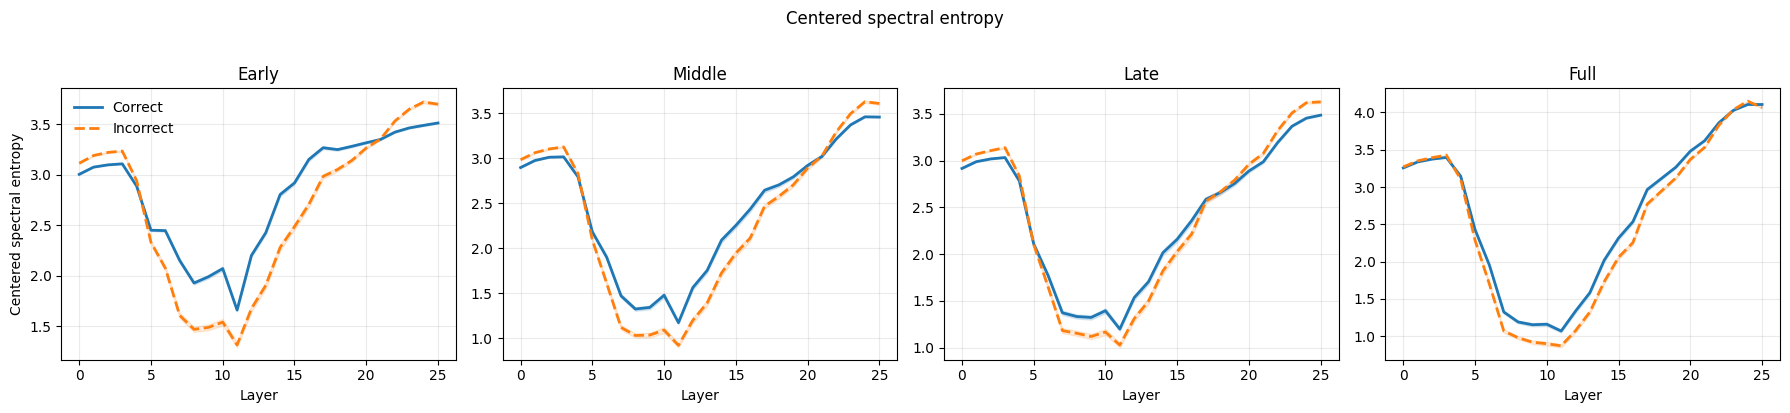

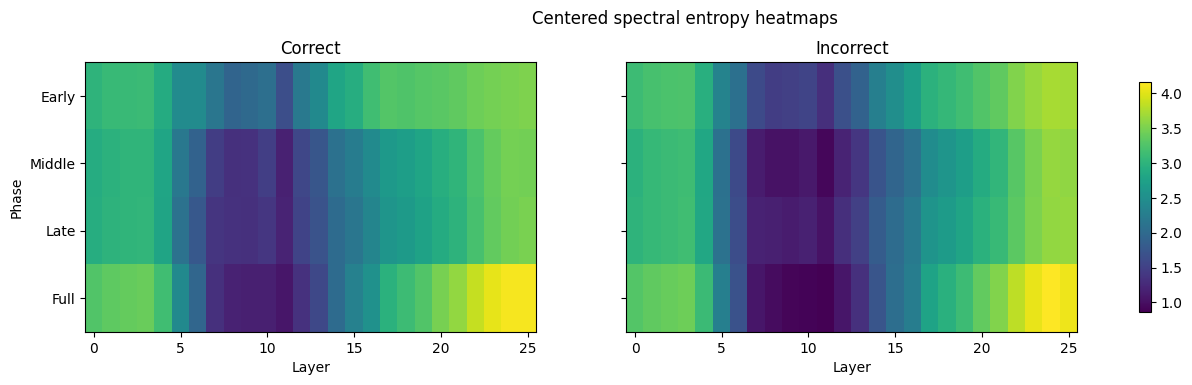

In [7]:
plot_scalar(
    CENTERED,
    "spectral_entropy",
    "Centered spectral entropy",
    "centered_spectral_entropy",
)

## Centered normalized spectral entropy

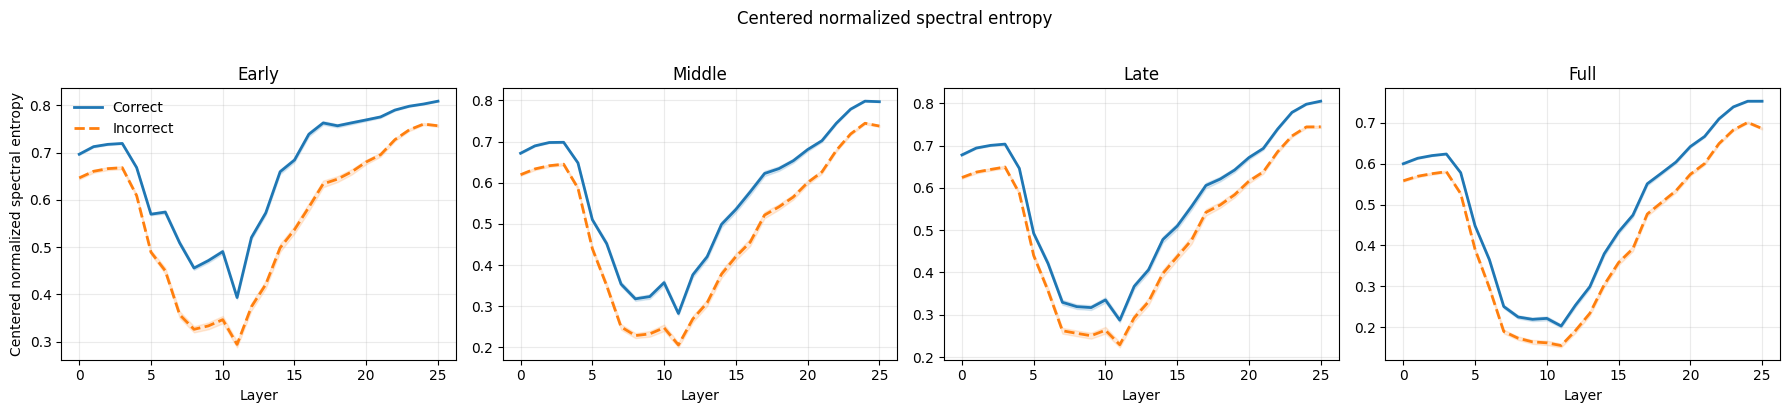

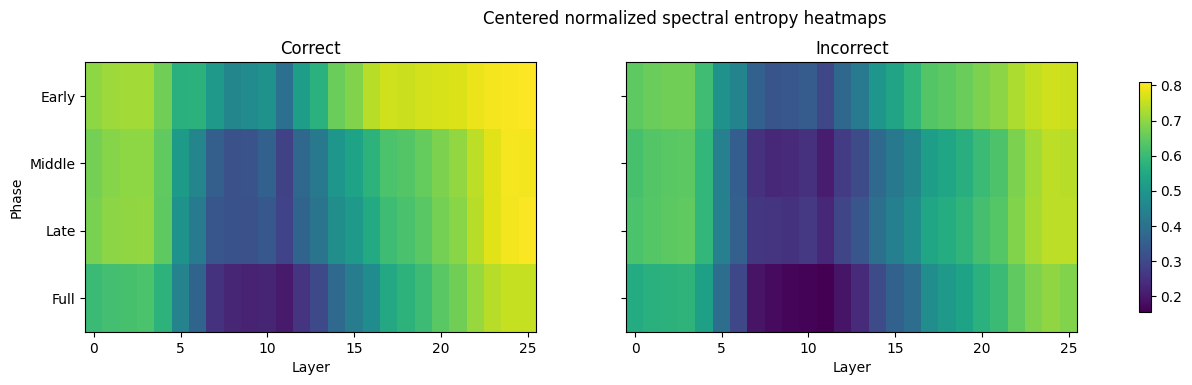

In [8]:
plot_scalar(
    CENTERED,
    "normalized_spectral_entropy",
    "Centered normalized spectral entropy",
    "centered_normalized_spectral_entropy",
)

## Centered LTO effective rank

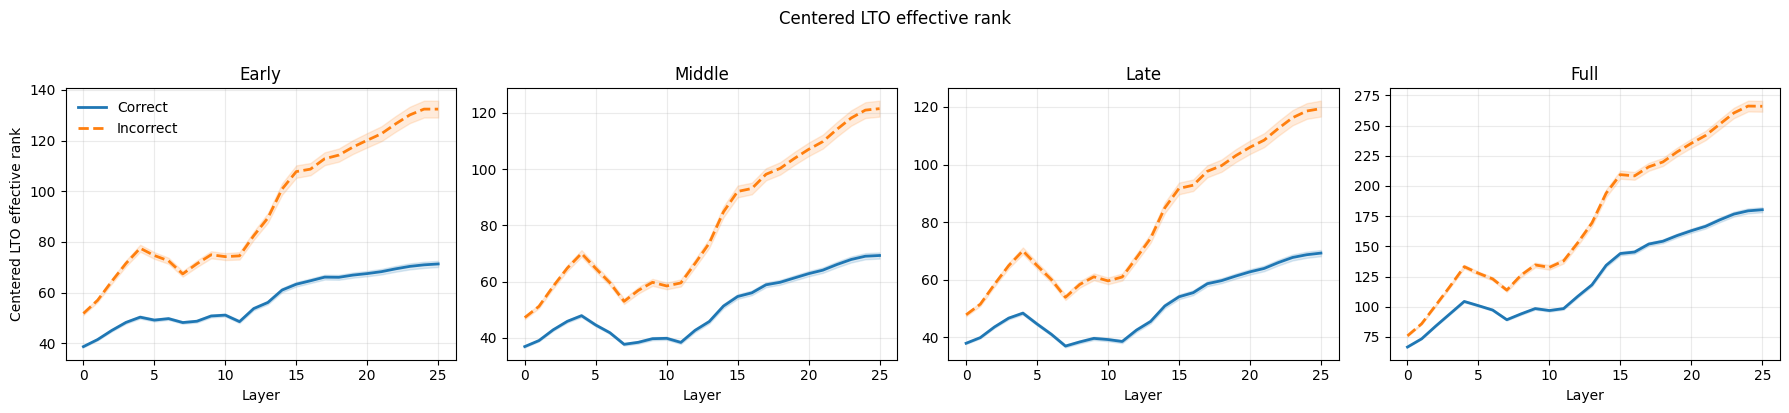

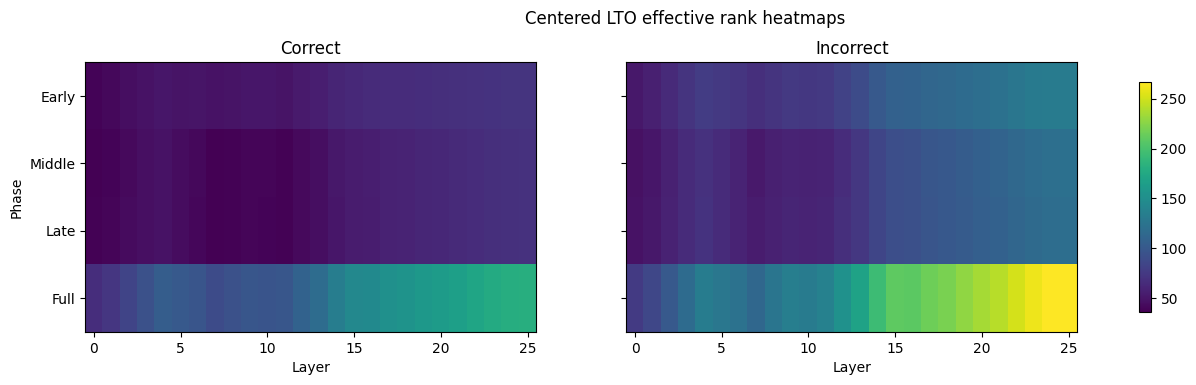

In [9]:
plot_scalar(
    CENTERED,
    "lto_effective_rank",
    "Centered LTO effective rank",
    "centered_lto_effective_rank",
)

## Centered normalized effective rank

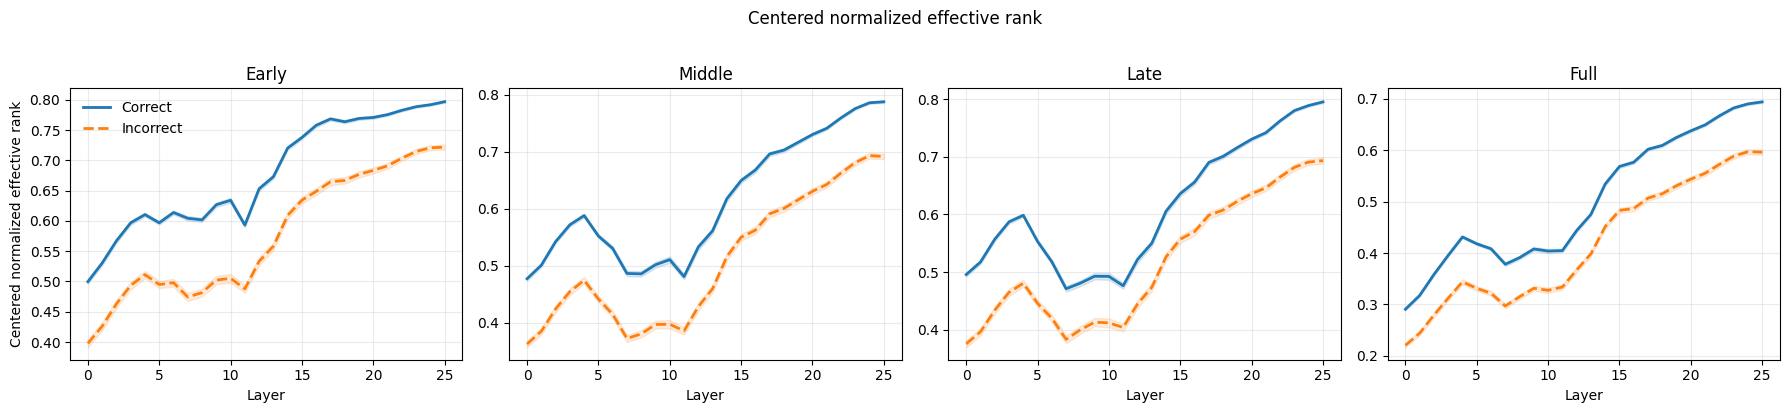

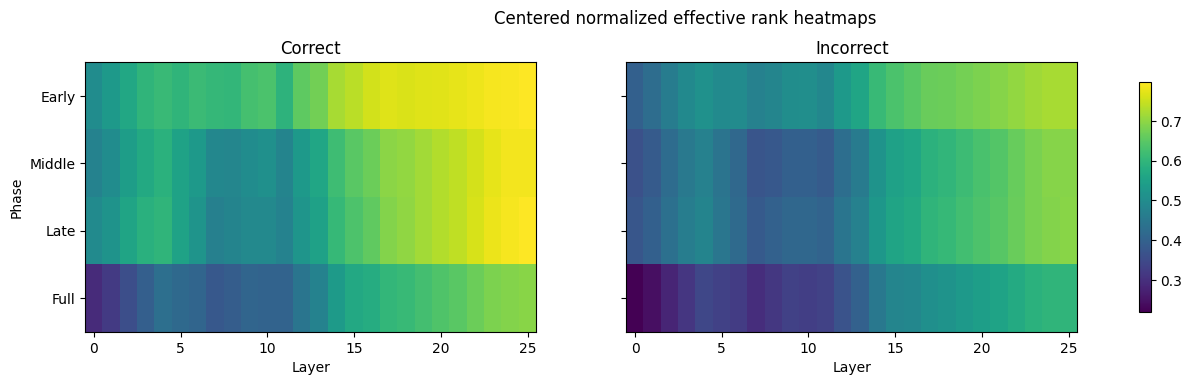

In [10]:
plot_scalar(
    CENTERED,
    "normalized_effective_rank",
    "Centered normalized effective rank",
    "centered_normalized_effective_rank",
)

## Centered LTO anisotropy

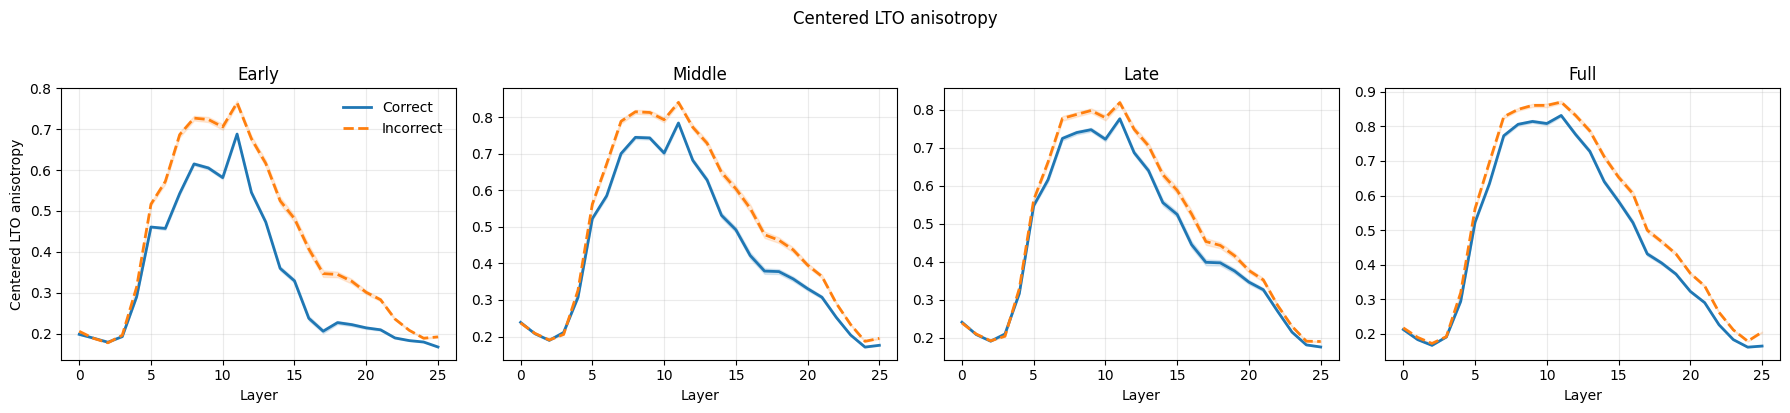

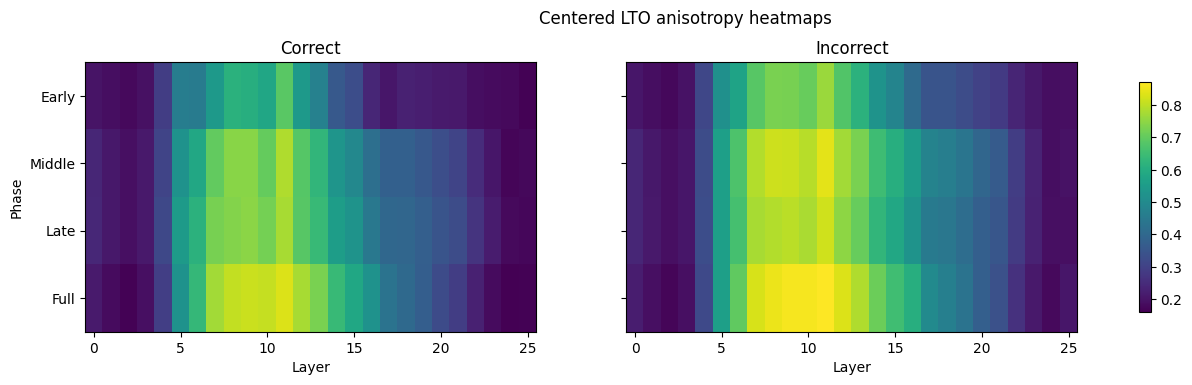

In [11]:
plot_scalar(
    CENTERED,
    "anisotropy",
    "Centered LTO anisotropy",
    "centered_lto_anisotropy",
)

## Centered top-1 singular value

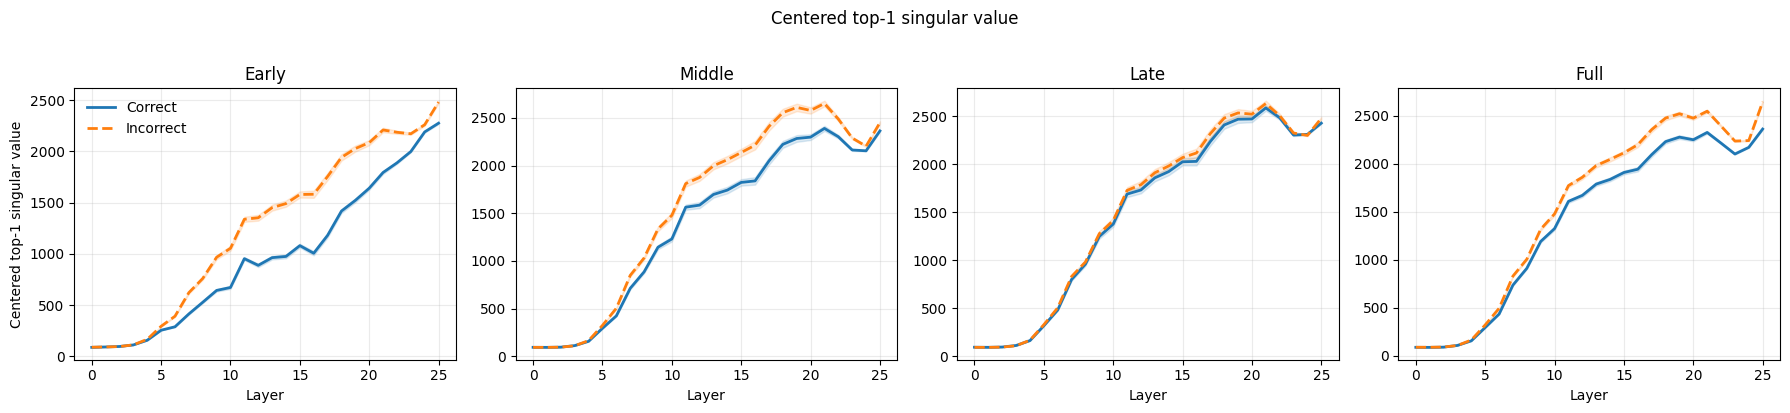

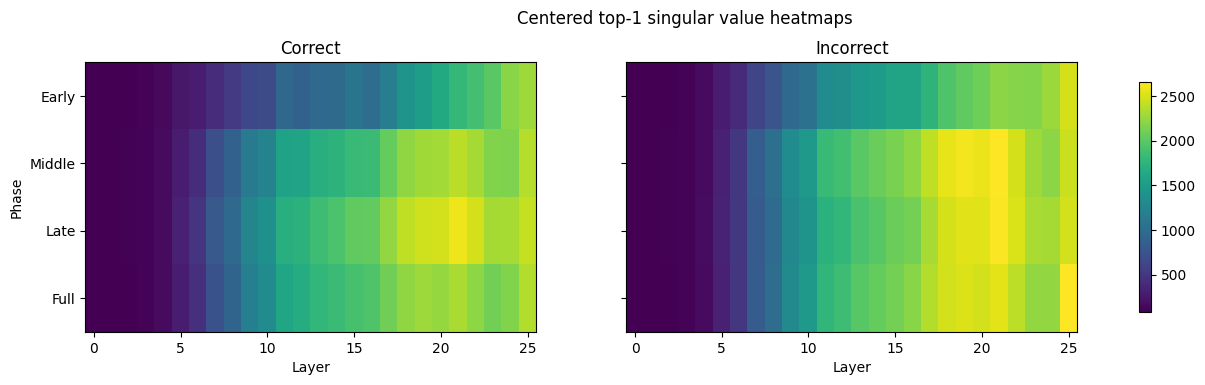

In [12]:
plot_scalar(
    CENTERED,
    "top1_singular_value",
    "Centered top-1 singular value",
    "centered_top1_singular_value",
)

## Centered top-1 energy fraction

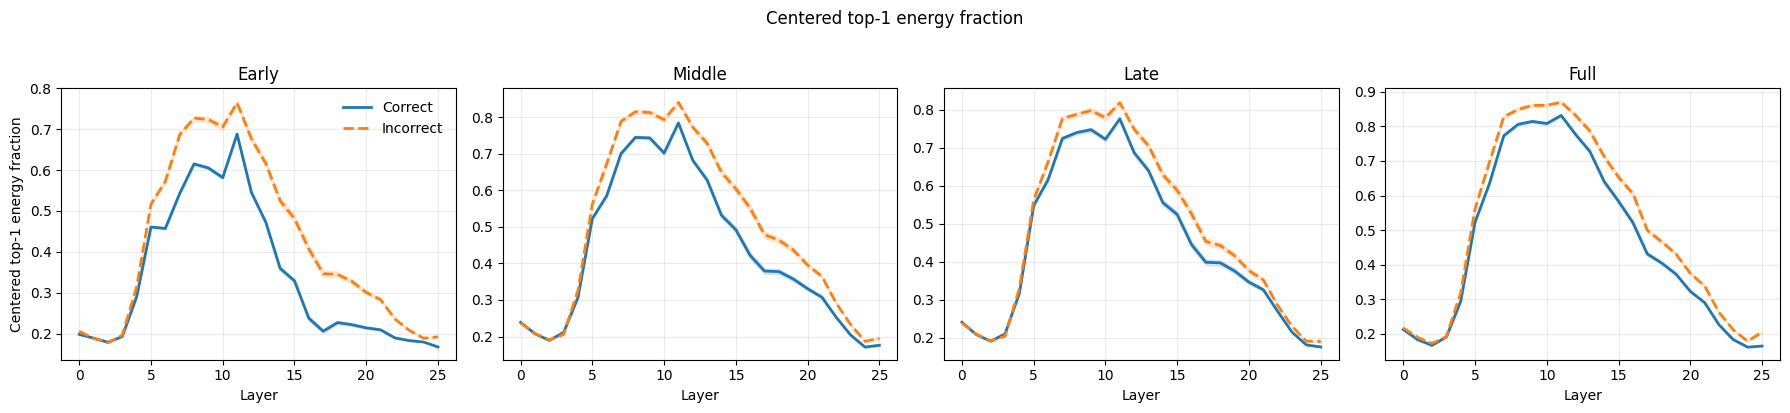

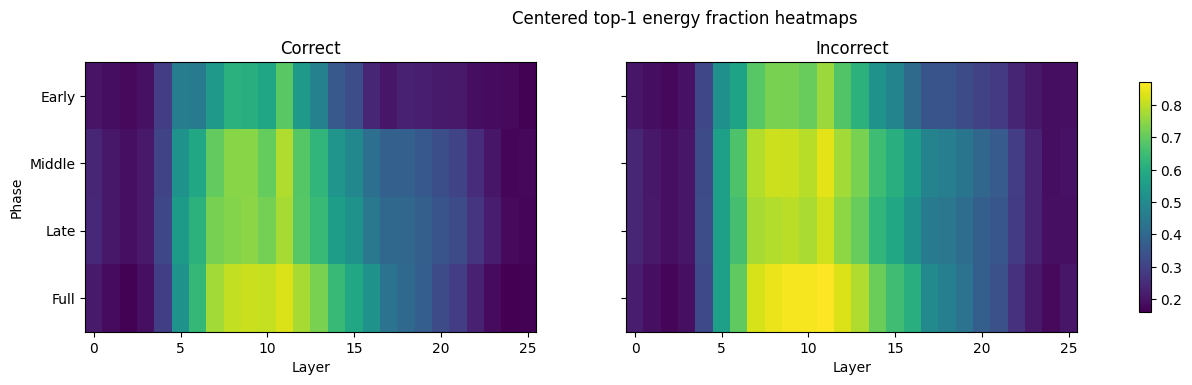

In [13]:
np.testing.assert_allclose(
    CENTERED["anisotropy"],
    CENTERED["energy_fraction_1"],
    rtol=1e-6,
    atol=1e-8,
)

plot_scalar(
    CENTERED,
    "energy_fraction_1",
    "Centered top-1 energy fraction",
    "centered_top1_energy_fraction",
)

## Centered top-5 energy fractions

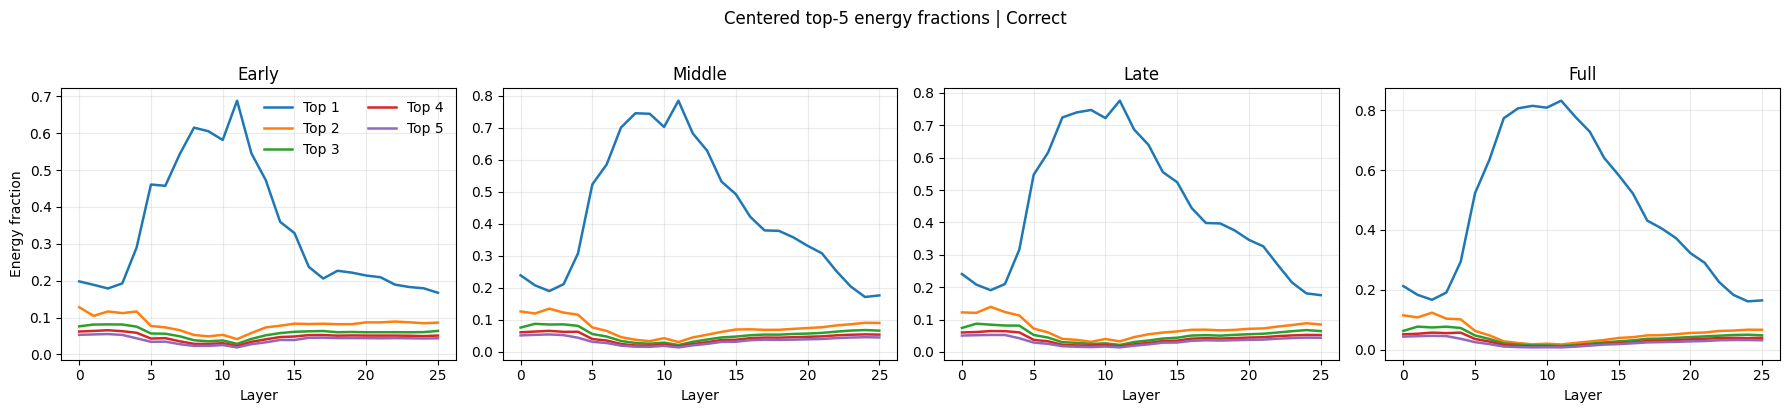

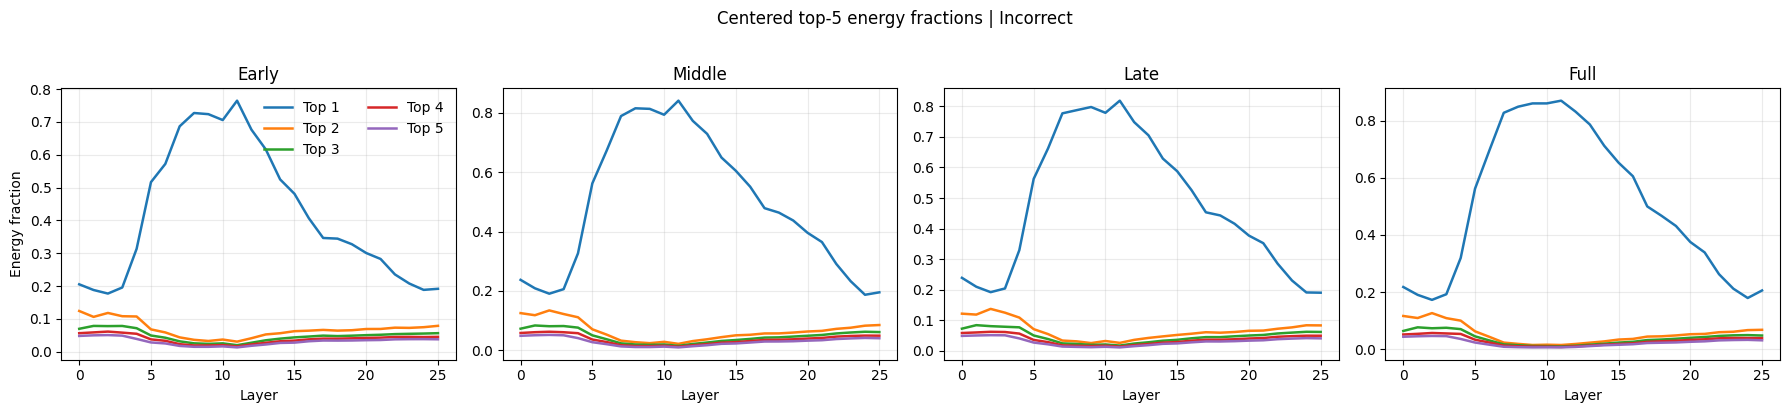

In [14]:
plot_top_five(
    CENTERED,
    "Centered top-5 energy fractions",
    "centered_top5_energy_fractions",
)

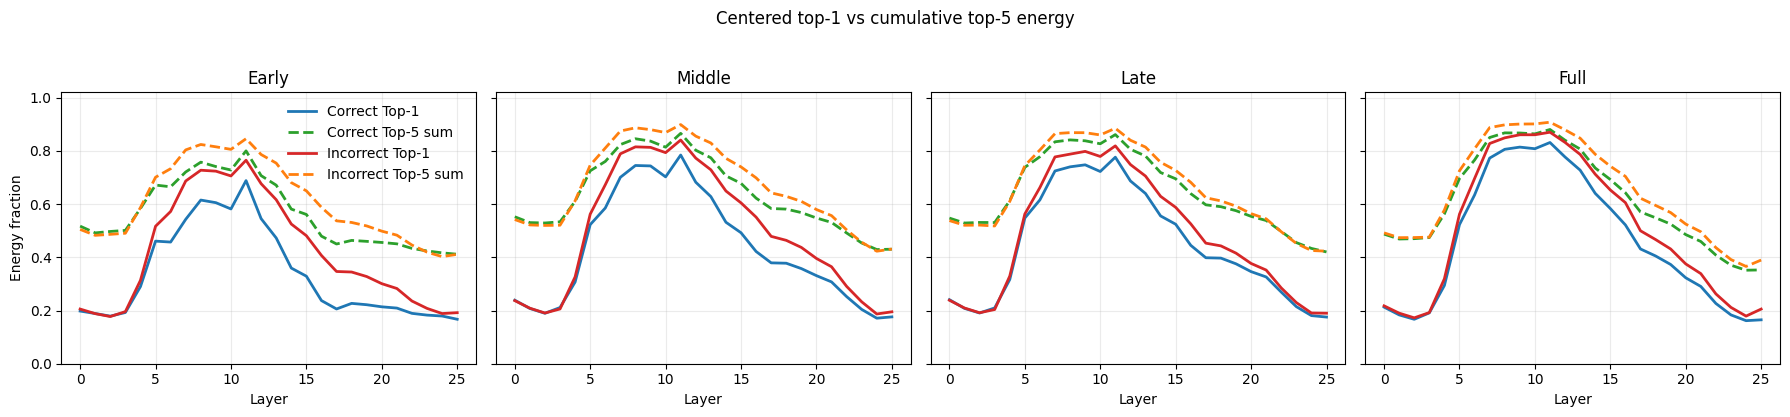

In [17]:
# Centered: compare top-1 energy with cumulative top-5 energy

df = CENTERED.copy()

energy_cols = [
    f"energy_fraction_{i}"
    for i in range(1, 6)
]

df["top5_energy_sum"] = df[energy_cols].sum(axis=1)

summary = (
    df.groupby(
        ["label", "phase", "layer"],
        as_index=False,
    )[
        [
            "energy_fraction_1",
            "top5_energy_sum",
        ]
    ]
    .mean()
)

colors = {
    ("Correct", "top1"): "tab:blue",
    ("Correct", "top5"): "tab:green",
    ("Incorrect", "top1"): "tab:red",
    ("Incorrect", "top5"): "tab:orange",
}

fig, axes = plt.subplots(
    1,
    len(PHASES),
    figsize=(18, 4),
    sharey=True,
)

for ax, phase in zip(axes, PHASES):
    phase_data = summary[
        summary["phase"] == phase
    ]

    for label in LABELS:
        values = (
            phase_data[
                phase_data["label"] == label
            ]
            .sort_values("layer")
        )

        ax.plot(
            values["layer"],
            values["energy_fraction_1"],
            color=colors[(label, "top1")],
            linewidth=2,
            label=f"{label} Top-1",
        )

        ax.plot(
            values["layer"],
            values["top5_energy_sum"],
            color=colors[(label, "top5")],
            linestyle="--",
            linewidth=2,
            label=f"{label} Top-5 sum",
        )

    ax.set_title(phase.capitalize())
    ax.set_xlabel("Layer")
    ax.set_ylim(0, 1.02)
    ax.grid(alpha=0.25)

axes[0].set_ylabel("Energy fraction")
axes[0].legend(frameon=False)

fig.suptitle(
    "Centered top-1 vs cumulative top-5 energy",
    y=1.03,
)

fig.tight_layout()
plt.show()

# Uncentered LTO analysis

## Compute or load uncentered metrics

In [15]:
UNCENTERED_PATH = (
    OUTPUT_DIR
    / "uncentered_metrics.parquet"
)

if UNCENTERED_PATH.is_file():
    UNCENTERED = pd.read_parquet(
        UNCENTERED_PATH
    )
else:
    UNCENTERED = build_metric_cache(
        centered=False
    )

print("Uncentered rows:", len(UNCENTERED))
display(UNCENTERED.head())


# UNCENTERED_PATH = (
#     OUTPUT_DIR
#     / "uncentered_metrics.parquet"
# )

# if UNCENTERED_PATH.is_file():
#     UNCENTERED = pd.read_parquet(
#         UNCENTERED_PATH
#     )

# else:
#     uncentered_rows = []

#     for rollout in tqdm(
#         RAW_DATA,
#         desc="Computing uncentered metrics",
#     ):
#         metric_rows = rollout_metrics(
#             rollout["hidden"],
#             rollout["phase_ranges"],
#             centered=False,
#         )

#         for metric_row in metric_rows:
#             metric_row.update({
#                 "prompt_id": rollout["prompt_id"],
#                 "rollout_key": rollout["rollout_key"],
#                 "rollout_id": rollout["rollout_id"],
#                 "label": rollout["label"],
#             })

#         uncentered_rows.extend(metric_rows)

#     UNCENTERED = pd.DataFrame(
#         uncentered_rows
#     )

#     UNCENTERED.to_parquet(
#         UNCENTERED_PATH,
#         index=False,
#     )

# print("Uncentered rows:", len(UNCENTERED))
# display(UNCENTERED.head())

## LTO spectral entropy

In [ ]:
plot_scalar(
    UNCENTERED,
    "spectral_entropy",
    "LTO spectral entropy",
    "lto_spectral_entropy",
)

## LTO normalized spectral entropy

In [ ]:
plot_scalar(
    UNCENTERED,
    "normalized_spectral_entropy",
    "LTO normalized spectral entropy",
    "lto_normalized_spectral_entropy",
)

## LTO effective rank

In [ ]:
plot_scalar(
    UNCENTERED,
    "lto_effective_rank",
    "LTO effective rank",
    "lto_effective_rank",
)

## LTO normalized effective rank

In [ ]:
plot_scalar(
    UNCENTERED,
    "normalized_effective_rank",
    "LTO normalized effective rank",
    "lto_normalized_effective_rank",
)

## LTO anisotropy

In [ ]:
plot_scalar(
    UNCENTERED,
    "anisotropy",
    "LTO anisotropy",
    "lto_anisotropy",
)

## LTO top-1 singular value

In [ ]:
plot_scalar(
    UNCENTERED,
    "top1_singular_value",
    "LTO top-1 singular value",
    "lto_top1_singular_value",
)

## LTO top-1 energy fraction

In [ ]:
np.testing.assert_allclose(
    UNCENTERED["anisotropy"],
    UNCENTERED["energy_fraction_1"],
    rtol=1e-6,
    atol=1e-8,
)

plot_scalar(
    UNCENTERED,
    "energy_fraction_1",
    "LTO top-1 energy fraction",
    "lto_top1_energy_fraction",
)

## LTO top-5 energy fractions

In [ ]:
plot_top_five(
    UNCENTERED,
    "LTO top-5 energy fractions",
    "lto_top5_energy_fractions",
)

## Files

In [ ]:
print("Centered metrics:", CENTERED_PATH)
print("Uncentered metrics:", UNCENTERED_PATH)
print("Figures:", FIGURE_DIR)
print("Chunk cache:", CACHE_DIR)